# 12 | Integrate connectivity uncertainty, cognition and context

**Goal:** examine the complete clinical profile alongside measured network changes and conditional uncertainty, without reducing the patient to one network metric or an invented cognitive score.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## Four evidence layers
1. Raw clinical values and changes: 28 CANTAB measures and 19 psychosocial/context fields, with original units, missingness and coding caveats.
2. Observed SC, FC and SC–FC point summaries, under the recommended fixed policy.
3. Conditional repeat/sampling ranges and frozen-versus-refitted nuisance sensitivity.
4. Candidate task/network hypotheses, retained from notebook 04, **not individual localization or fitted prediction**.

Context fields have no assigned brain network. Faster RTI and longer SSP coexist with slower MOT, mixed SOC/RVP and mixed emotional/social outcomes. Lower FC is not uniformly worse cognition. No dedicated quality-of-life instrument, clinical repeat-error estimate, norm-adjusted reliable-change threshold or sufficient observations for a clinical association model is supplied.

Main evidence: full-run points plus fully refitted 97-frame stability ranges. Earlier bootstrap evidence is retained in evidence_integration/.


,task,domain,candidate_networks,interpretive_limit
0,MOT,Sensorimotor / visual attention,SomMot; Vis,latency and spatial error; no isolated motor d...
1,RTI,"Speeded detection, decision and motor execution",DorsAttn; SalVentAttn; SomMot,reaction and movement times differ; ceiling ac...
2,RVP,Sustained attention / target detection,DorsAttn; SalVentAttn; Cont,A-prime and hit probability vs latency and fal...
3,SOC,Planning / executive control,Cont; DorsAttn,problem difficulty matters; 4-move and 5-move ...
4,SSP,Visuospatial short-term memory,DorsAttn; Cont; Vis,span is one raw ordinal score; practice effect...


group                 availability
CANTAB                paired          28
psychosocial/context  paired          10
                      post-only        4
                      pre-only         5
Name: fields, dtype: int64

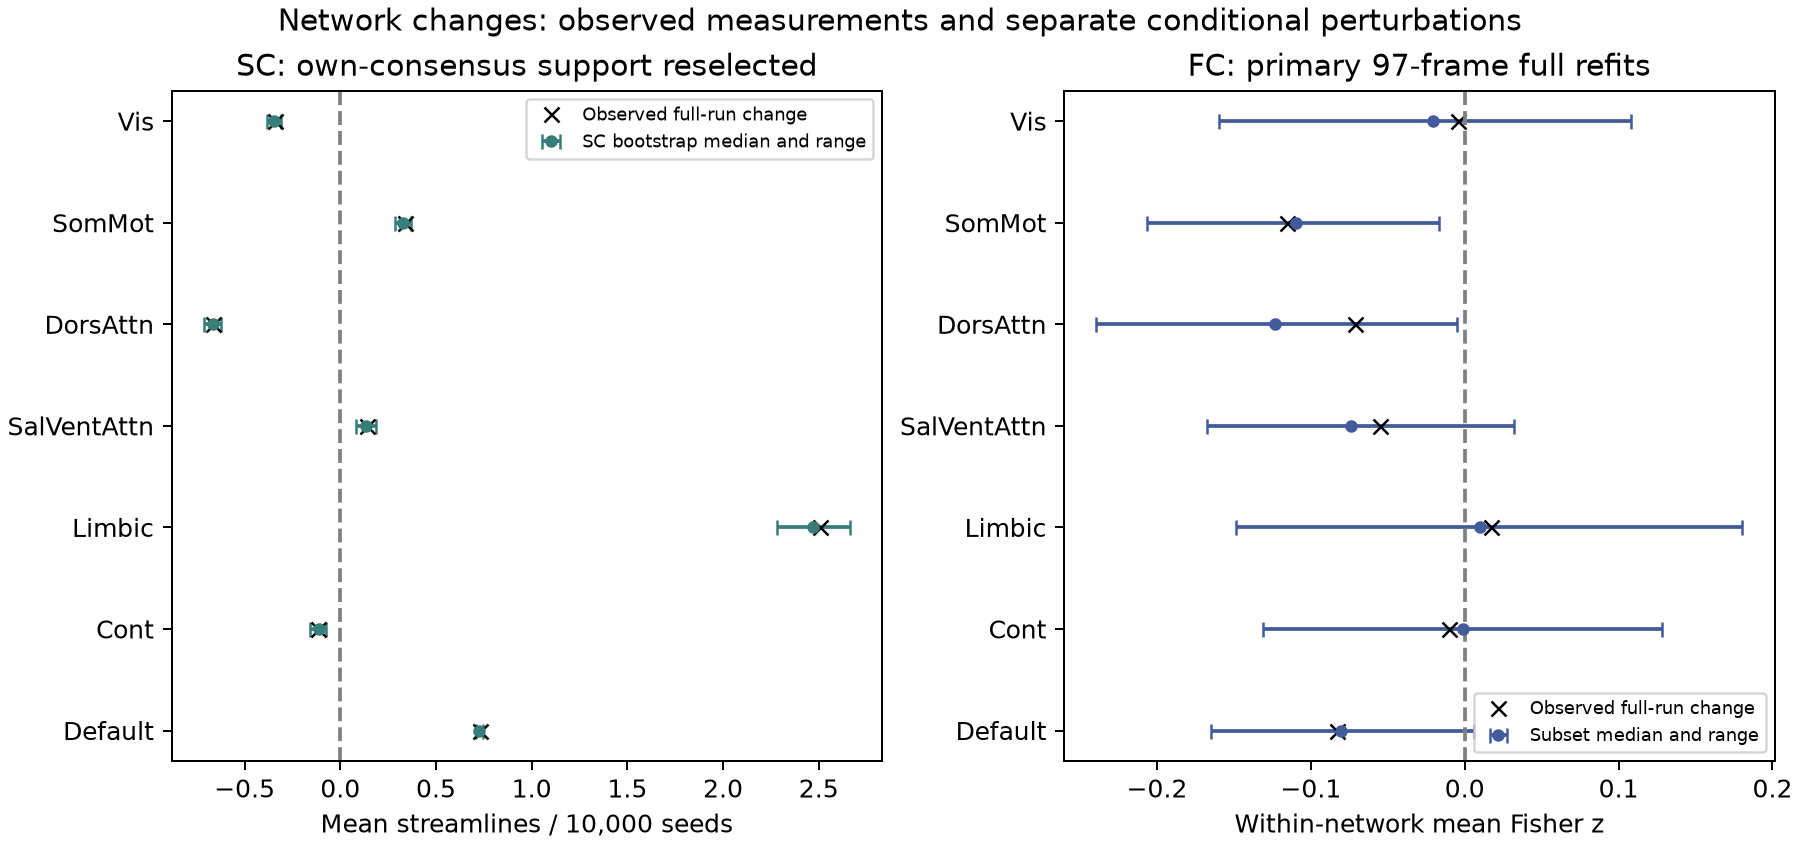

In [2]:
EVIDENCE=RESULTS/"evidence_integration"
ledger=pd.read_csv(RESULTS/"primary_fc/clinical_evidence_ledger.csv")
network_ranges=pd.read_csv(RESULTS/"primary_fc/network_uncertainty.csv").query("role=='primary'")
print("Main evidence: full-run points plus fully refitted 97-frame stability ranges. Earlier bootstrap evidence is retained in evidence_integration/.")
display(pd.read_csv(EVIDENCE/"task_network_hypotheses.csv"))
display(ledger.groupby(["group","availability"]).size().rename("fields"))
display(Image(filename=str(RESULTS/"figures/primary_fc_network_changes.png")))

## A field-by-field evidence browser
Select any source field. Candidate networks are broad didactic links shared across tasks. Network FC is the mean Fisher-z of **all within-network pairs**, including those without SC support; network SC is mean own-consensus weight over the same fixed anatomical pair population, including absent zero weights. SC reselects own 16/20 support in each whole-run bootstrap. Primary FC uses 200 nonreplacement 97-frame block-10 draws with complete nuisance refitting. Frozen/coefficient fits and earlier bootstrap ranges remain sensitivity evidence in notebooks 11/13/14. These network averages differ from Spearman coupling on the 823 shared SC connections; their directions need not agree.

SC and FC axes have different units and perturbation sources. Clinical changes are displayed separately in original units; no uncertainty bars are invented for them. Context scores describe reported experience/participation, and can motivate future measurement, but their causal influence here is not estimated. Post-only “Same/Less” responses remain relative categories and do not fill numeric postoperative baselines.

In [3]:
def assessment_browser(measure="rti_simple_rt_mean"):
    r=ledger[ledger.measure==measure].iloc[0]
    display(r[["measure","description","group","preop","postop","delta_post_minus_pre","units","direction_text","availability","definition","caveat","integration_role","candidate_networks","link_status"]].to_frame("value"))
    if pd.isna(r.candidate_networks):
        display(Markdown("**Unlocalized context.** Examine this field with the mixed cognitive profile and missingness; no network is assigned and no causal adjustment is possible."));return
    names=r.candidate_networks.split("; ")
    display(network_ranges[network_ranges.network.isin(names)][["network","modality","mode","units","preop","postop","observed_delta","median","q025","q975"]])
widgets.interact(assessment_browser,measure=widgets.Dropdown(options=ledger.measure.tolist(),value="rti_simple_rt_mean"))

,value
measure,rti_simple_rt_mean
description,CANTAB Reaction Time — simple: mean reaction time
group,CANTAB
preop,403.78
postop,345.5555555556
delta_post_minus_pre,-58.224444
units,ms
direction_text,"Lower is nominally faster, more precise or mor..."
availability,paired
definition,Reaction Time - simple: mean reaction time; ta...


,network,modality,mode,units,preop,postop,observed_delta,median,q025,q975
28,SomMot,SC,own_reselected,mean streamlines / 10000 attempted seeds,2.579487,2.915751,0.336264,0.327839,0.283402,0.371245
43,SomMot,FC,full_refit,mean Fisher z,0.265161,0.149400,-0.115760,-0.109317,-0.206384,-0.016997
56,DorsAttn,SC,own_reselected,mean streamlines / 10000 attempted seeds,1.707143,1.041746,-0.665397,-0.665317,-0.712429,-0.623627
71,DorsAttn,FC,full_refit,mean Fisher z,0.254676,0.183384,-0.071292,-0.123442,-0.239322,-0.004977
84,SalVentAttn,SC,own_reselected,mean streamlines / 10000 attempted seeds,2.034848,2.172980,0.138131,0.136995,0.082298,0.187386
99,SalVentAttn,FC,full_refit,mean Fisher z,0.202582,0.147258,-0.055324,-0.074004,-0.167222,0.031901


interactive(children=(Dropdown(description='measure', index=23, options=('stai', 'pswq', 'erq_reappraisal', 'e…

<function __main__.assessment_browser(measure='rti_simple_rt_mean')>

,network,modality,protocol,mode,role,units,edges,preop,postop,observed_delta,draws,q025,median,q975,sd,positive_fraction
28,SomMot,SC,whole_run_bootstrap,own_reselected,primary,mean streamlines / 10000 attempted seeds,91,2.579487,2.915751,0.336264,500,0.283402,0.327839,0.371245,0.023036,1.00
43,SomMot,FC,two_thirds_block10,full_refit,primary,mean Fisher z,91,0.265161,0.149400,-0.115760,200,-0.206384,-0.109317,-0.016997,0.051992,0.01


,measure,preop,postop,delta_post_minus_pre,units,caveat
19,mot_latency_mean,817.8,844.5,26.700000,ms,"Screening performance combines comprehension, ..."
20,mot_latency_md,797.5,861.5,64.000000,ms,"Screening performance combines comprehension, ..."
21,mot_error_mean,8.69,9.6672619393,0.977262,pixels,"Screening performance combines comprehension, ..."
22,rti_simple_accuracy,9,9,0.000000,correct responses,Source maxima are 9 for simple and 8 for five-...
23,rti_simple_rt_mean,403.78,345.5555555556,-58.224444,ms,"Raw score; no age-adjusted norm, individual re..."
24,rti_simple_rt_md,391,325,-66.000000,ms,"Raw score; no age-adjusted norm, individual re..."
25,rti_simple_rt_sd,48.69,51.7544952422,3.064495,ms,Trial-to-trial variability is distinct from me...
26,rti_simple_mt_mean,504.44,426.3333333333,-78.106667,ms,"Raw score; no age-adjusted norm, individual re..."
27,rti_simple_mt_md,484,423,-61.000000,ms,"Raw score; no age-adjusted norm, individual re..."
28,rti_simple_mt_sd,68.17,61.3208773584,-6.849123,ms,Trial-to-trial variability is distinct from me...


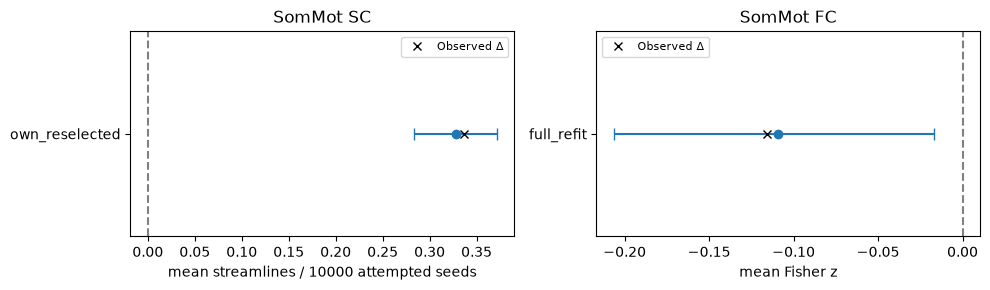

interactive(children=(Dropdown(description='network', index=1, options=('Vis', 'SomMot', 'DorsAttn', 'SalVentA…

<function __main__.network_evidence(network='SomMot')>

In [4]:
def network_evidence(network="SomMot"):
    v=network_ranges[network_ranges.network==network]
    display(v)
    linked=ledger[ledger.candidate_networks.fillna("").str.split("; ").apply(lambda names:network in names)]
    display(linked[["measure","preop","postop","delta_post_minus_pre","units","caveat"]])
    fig,axs=plt.subplots(1,2,figsize=(10,3))
    for ax,mod in zip(axs,["SC","FC"]):
        w=v[v.modality==mod];y=np.arange(len(w))
        ax.errorbar(w["median"],y,xerr=np.vstack([w["median"]-w.q025,w.q975-w["median"]]),fmt="o",capsize=4)
        ax.plot(w.observed_delta,y,"x",color="black",label="Observed Δ");ax.axvline(0,color="gray",ls="--")
        ax.set_yticks(y,w["mode"]);ax.set_title(network+" "+mod);ax.set_xlabel(w.units.iloc[0]);ax.legend(fontsize=8)
    plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(network_evidence,network=widgets.Dropdown(options=nodes.network.unique().tolist(),value="SomMot"))

## New sampling-design comparison
Notebook [13](13_pc_sampling_mechanisms.ipynb) finds that repeated-frame weights substantially change the learned PCA subspace. At block 10, removing multiplicities at identical coverage moves visual-network median Δ from −0.1993 to −0.0458, closer to the observed −0.0045; independent matched-count blocks give −0.0355. The sensorimotor matched-count range crosses zero. Dorsal-attention/default subset ranges can stay negative without establishing clinical localization. Compare all designs in original FC units below. The 80% ranges depend on retained fraction and are not full-run confidence intervals.

In [5]:
sampling_networks=pd.read_csv(RESULTS/"pc_sampling/network_ranges.csv")
from pat16.pc_sampling_figures import LABELS as SAMPLING_LABELS
def clinical_sampling_comparison(measure="rti_simple_rt_mean",mode="full_refit",block=10):
    r=ledger[ledger.measure==measure].iloc[0]
    display(r[["description","preop","postop","delta_post_minus_pre","units","availability","caveat"]].to_frame("Clinical source evidence"))
    if pd.isna(r.candidate_networks):
        display(Markdown("Context is unlocalized; no network association or QoL score is calculated."));return
    names=r.candidate_networks.split("; ")
    v=sampling_networks[sampling_networks.network.isin(names)&(sampling_networks["mode"]==mode)&(sampling_networks.protocol.str.endswith("block"+str(block)))]
    display(v[["protocol","network","observed_delta","median","q025","q975"]])
widgets.interact(clinical_sampling_comparison,measure=widgets.Dropdown(options=ledger.measure.tolist(),value="rti_simple_rt_mean"),mode=widgets.Dropdown(options=["frozen","coefficients","full_refit"],value="full_refit"),block=widgets.Dropdown(options=[5,10,20],value=10))

,Clinical source evidence
description,CANTAB Reaction Time — simple: mean reaction time
preop,403.78
postop,345.5555555556
delta_post_minus_pre,-58.224444
units,ms
availability,paired
caveat,"Raw score; no age-adjusted norm, individual re..."


,protocol,network,observed_delta,median,q025,q975
99,bootstrap_block10,SomMot,-0.115760,-0.225193,-0.429788,-0.023769
100,bootstrap_block10,DorsAttn,-0.071292,-0.214471,-0.415071,0.009675
101,bootstrap_block10,SalVentAttn,-0.055324,-0.128612,-0.308414,0.026341
120,unit_coverage_block10,SomMot,-0.115760,-0.114787,-0.237140,-0.001568
121,unit_coverage_block10,DorsAttn,-0.071292,-0.125610,-0.278125,-0.015987
122,unit_coverage_block10,SalVentAttn,-0.055324,-0.070016,-0.178825,0.026947
141,block_unique_block10,SomMot,-0.115760,-0.112538,-0.223434,0.024579
142,block_unique_block10,DorsAttn,-0.071292,-0.120288,-0.249293,-0.014811
143,block_unique_block10,SalVentAttn,-0.055324,-0.072282,-0.180562,0.022525
162,block80_block10,SomMot,-0.115760,-0.106246,-0.170161,-0.031897


interactive(children=(Dropdown(description='measure', index=23, options=('stai', 'pswq', 'erq_reappraisal', 'e…

<function __main__.clinical_sampling_comparison(measure='rti_simple_rt_mean', mode='full_refit', block=10)>

## What do these calculations change about interpretation?
The recommended primary coupling median is −0.04694 with range [−0.10261,+0.00832]; its observed full-run change remains −0.04173. Sensorimotor primary range [−0.2064,−0.0170] is negative, whereas a prior matched-count design crossed zero. Visual [−0.1594,+0.1081], control [−0.1312,+0.1283] and default [−0.1649,+0.0058] cross zero. This is sampling-design sensitivity, not a diagnosis or a clinical error estimate. The measured CANTAB/context profile is unchanged.

Full nuisance retraining adds uncertainty about the estimator, while measured CANTAB changes remain unchanged. Assess the entire profile against the network ranges: a negative sensorimotor FC contrast may coexist with both slower MOT and faster RTI because they have different motor/attention/task requirements. A small control-network mean contrast does not demonstrate preserved executive circuitry, and a span gain cannot establish compensation. Anxiety, worry, loneliness and employment move in different directions; they do not define a single QoL trajectory.

The bootstrap global primary coupling ranges include zero under frozen and full refits. Matched-count nonreplacement blocks also cross zero; 80% ranges are narrower and negative but change the conditional sampling target. Their sign does not resolve biological direction. Strict full-run refits often fail the explicit distinct-frame guard; the earlier matched duration/FD/run-half results remain conditional sensitivity evidence, with strict pre-op FC fixed by its 68 eligible frames. Do not choose denoising, support, block length or a cognitive outcome by the desired sign.

**Next measurements to test hypotheses:** dated assessments and surgery/treatment timeline; retest norms and practice/reliability information; fatigue/sleep/medication and physiological context; longer repeat resting scans; expert lesion/mask/tract review; a dedicated validated QoL/participation instrument. These are evidence needs, not inferred patient facts. No two-observation correlation, cognitive composite, reliable-change test or treatment effect is calculated.

Run `uv run python scripts/integrate_clinical_evidence.py`. The 47-row evidence ledger, per-network draws/ranges and input/output hashes are in `results/evidence_integration/`. Report Appendices A1/A2 preserve the complete field dictionaries and all source values.